In [ ]:
"""
%pip install pandas
%pip install numpy
%pip install matplotlib
%pip install PIL
%pip install pathlib
%pip install scikit-learn
%pip install torch
%pip install torch torchvision
%pip install openpyxl
"""

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

from sklearn.model_selection import StratifiedGroupKFold

import torch
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader

# Loading in the data

In [ ]:
ROOT = Path(".")
IMG_DIR = ROOT / "Image"

FOLDERS = ["Normal", "Stage 1 ROP", "Stage 2 ROP", "Stage 3 ROP", "Stage 4 ROP", "Stage 5 ROP"]

# one row per image file, stacked across class folders
files = pd.concat(
    [pd.DataFrame({"image": [p.name for p in sorted((IMG_DIR / f).iterdir())
                             if p.suffix.lower() in {".jpg", ".jpeg"}],
                   "label": f})
     for f in FOLDERS],
    ignore_index=True,
)
files["path"] = [str(IMG_DIR / lab / name) for lab, name in zip(files["label"], files["image"])]

# attach patient metadata by filename
info = pd.read_excel(ROOT / "img_info.xlsx")
imgs = files.merge(info, on="image", how="left", validate="one_to_one").rename(columns={"image": "file"})
assert imgs["patient_id"].notna().all(), "some images are missing from img_info.xlsx"

SEVERITY = {"Stage 1 ROP": "Mild ROP", "Stage 2 ROP": "Mild ROP", "Stage 3 ROP": "Moderate ROP",
            "Stage 4 ROP": "Severe ROP", "Stage 5 ROP": "Severe ROP"}
imgs["severity"] = imgs["label"].map(SEVERITY)           
imgs["ROP"] = (imgs["label"] != "Normal").astype(int)    

print("imgs:", imgs.shape[0])
print("features:", imgs.columns)

imgs: 1527
features: Index(['file', 'label', 'path', 'patient_id', 'gender', 'gestational_age',
       'birth_weight', 'plurality', 'delivery_mode', 'categories', 'severity',
       'ROP'],
      dtype='str')


# Loading in the images

In [5]:
# Image dimensions when loaded in
size = 512

def load(p, size):
    with Image.open(p) as im:
        return np.asarray(im.convert("RGB").resize(size))

# Opening the jpeg images as numpy arrays with the standardized size
imgs["image"] = imgs["path"].apply(lambda p: load(p, (size,size)))   

# Better to seperate the memory heavy image data from the rest of the data
X_all = np.stack(imgs["image"].values)
imgs = imgs.drop(columns="image")

# ~1m or less

# 5-fold cross-validation

In [ ]:
# Similar to the regular KFold() function but able to handle stratification
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
# Initilizing as -1 makes overlooking skipped rows harder to overlook
imgs["fold"] = -1
# y = label to stratify on, every group stays in the same fold (so patients stay in the same fold)
for k, (train_idx, val_idx) in enumerate(sgkf.split(X=imgs, y=imgs["label"], groups=imgs["patient_id"])):
    # assigning images to a fold
    imgs.loc[val_idx, "fold"] = k

print("every image is in a fold:", (imgs["fold"] >= 0).all())
print("No patient is split between folds:", imgs.groupby("patient_id")["fold"].nunique().max() == 1)

every image is in a fold: True
No patient is split between folds: True


# Data pre-processing and augmentation transformers

In [ ]:
# Compose() chains a list of transforms into a single callable that applies them in order
# where v2 is what is being transformed
train_tf = v2.Compose([
    v2.ToImage(),                                    # HWC uint8 array -> CHW tensor
    v2.ToDtype(torch.float32, scale=True),           # intensity normalization: [0, 255] -> [0, 1]
    v2.RandomHorizontalFlip(p=0.5),                  # random horizontal flip
    v2.RandomAffine(degrees=5, scale=(0.9, 1.1),     # rotation in [-5, 5] deg and scale in [0.9, 1.1], one resampling step
                    interpolation=v2.InterpolationMode.BILINEAR, fill=0),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.0),
])

val_tf = v2.Compose([                                # validation: normalization only
    v2.ToImage(),                                    # no augmentation
    v2.ToDtype(torch.float32, scale=True),
])

# Assigning a dataset for each task

In [ ]:
# ROP occurence task
occ_df = imgs.assign(y=imgs["ROP"])
# severity task
sev_df = imgs[imgs["severity"].notna()].assign(
    # encoding
    y=lambda d: d["severity"].map({"Mild ROP": 0, "Moderate ROP": 1, "Severe ROP": 2}))

print("-------[Occurence Task]-------")
print("occurence task unique patients:", occ_df["patient_id"].unique().shape[0])
print("occurence task images:", occ_df.shape[0])
print("num classes:", occ_df["ROP"].unique().shape[0])
print(pd.crosstab(imgs["ROP"], imgs["fold"]))
print("\n")
print("-------[Severity Task]-------")
print("severity task unique patients:", sev_df["patient_id"].unique().shape[0])
print("severity task images:", sev_df.shape[0])
print("num classes:", sev_df["severity"].unique().shape[0])
print(pd.crosstab(imgs["severity"], imgs["fold"]))

-------[Occurence Task]-------
occurence task unique patients: 916
occurence task images: 1527
num classes: 2
fold    0    1    2    3    4
ROP                          
0     124  125  124  125  125
1     182  181  181  180  180


-------[Severity Task]-------
severity task unique patients: 550
severity task images: 904
num classes: 3
fold            0    1    2    3    4
severity                             
Mild ROP      116  114  115  114  115
Moderate ROP   48   49   48   48   48
Severe ROP     18   18   18   18   17


# Image Loader

In [ ]:
class ROPDataset(Dataset):
    """Hands the DataLoader one (image, label) pair at a time, applying the transform on the fly."""

    def __init__(self, X, idx, y, tf):
        # X   : the full image array (1527, 512, 512, 3), uint8. Stored by reference, not copied.
        # idx : row numbers in X that belong to this dataset (e.g. this fold's training rows)
        # y   : labels for those same rows, in the same order as idx
        # tf  : transform pipeline (train_tf or val_tf)
        # np.asarray turns the pandas Index / Series into plain numpy arrays
        self.X, self.idx, self.y, self.tf = X, np.asarray(idx), np.asarray(y), tf

    def __len__(self):
        # the DataLoader calls this to know how many samples there are (which sets batches per epoch)
        return len(self.idx)

    def __getitem__(self, i):
        # i is a position within this dataset (0 .. len-1), not a row number in X.
        # self.idx[i] translates it to the row in X, and self.X[...] is one (512, 512, 3) uint8 image.
        # self.tf(...) returns a float tensor (3, 512, 512). The random steps in train_tf are
        # re-drawn on every call, so the same image looks different each epoch (X itself isn't modified).
        # int(self.y[i]) is a plain Python int label; the DataLoader stacks these into a tensor.
        return self.tf(self.X[self.idx[i]]), int(self.y[i])


def make_loaders(df, k, bs=16):
    # df: occ_df or sev_df (needs "fold" and "y" columns). k: the fold held out for validation.
    tr, va = df[df["fold"] != k], df[df["fold"] == k]    # four folds to train on, one to validate on

    # tr.index holds the original row numbers in imgs / X_all (they survive the filtering),
    # and tr["y"] holds their labels in the same order
    train_dl = DataLoader(ROPDataset(X_all, tr.index, tr["y"], train_tf), batch_size=bs, shuffle=True)  # new order each epoch
    val_dl   = DataLoader(ROPDataset(X_all, va.index, va["y"], val_tf),   batch_size=bs)               # no shuffle: order stays fixed
    # DataLoader() provides effecient data handling during training and evaluation
    return train_dl, val_dl

# Testing augmentation

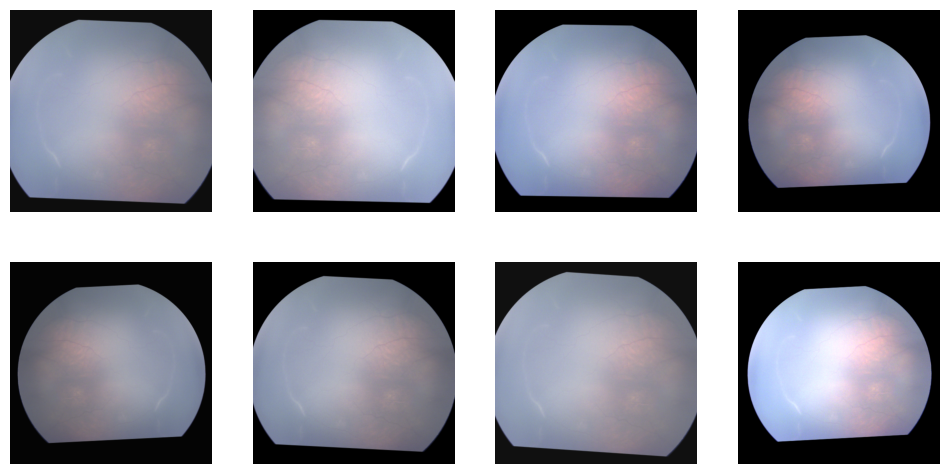

In [ ]:
# X_all is all the images only
img = X_all[sev_df.index[0]] # gets an index for the image data
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
# Do 8 times for the same image
for ax in axes.flat:
    ax.imshow(train_tf(img).permute(1, 2, 0).clamp(0, 1).numpy())
    # train_tf applies the transforms to a given image (roation, color jitter, etc)
    # permute() changes the tensors shape from (channels, height, width) to (hight, width, channels)
    # clamp(0,1) ensures the pixels are within a valid range for images
    # numpy() converts the tensor to a numpy array
    ax.axis("off")

# Checks

In [16]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

train_dl, val_dl = make_loaders(sev_df, k=0)
xb, yb = next(iter(train_dl))
print(xb.shape, xb.dtype, yb.dtype, float(xb.min()), float(xb.max()))
# expect torch.Size([16, 3, 512, 512]) torch.float32 torch.int64, values within [0, 1]

device: cpu
torch.Size([16, 3, 512, 512]) torch.float32 torch.int64 0.0 1.0


# Model

In [12]:
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

class ImageNetNorm(nn.Module):
    """Standardizes inputs with the statistics the pretrained backbone was trained on."""
    def __init__(self):
        super().__init__()
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        return (x - self.mean) / self.std

def build_model(n_classes, pretrained=True):
    net = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)   # downloads weights once
    net.fc = nn.Linear(net.fc.in_features, n_classes)    # new head: 512 features -> n_classes logits
    return nn.Sequential(ImageNetNorm(), net).to(device)

# Training and cross-validation functions

In [13]:
def run_epoch(model, dl, loss_fn, opt=None):
    training = opt is not None
    model.train(training)                          # eval mode freezes batch-norm statistics
    total, probs, ys = 0.0, [], []
    with torch.set_grad_enabled(training):         # no gradients needed for validation
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)                        # logits, shape (batch, n_classes)
            loss = loss_fn(out, yb)
            if training:
                opt.zero_grad(); loss.backward(); opt.step()
            else:
                probs.append(out.softmax(1).cpu()); ys.append(yb.cpu())
            total += loss.item() * len(yb)
    n = len(dl.dataset)
    return total / n if training else (total / n, torch.cat(probs).numpy(), torch.cat(ys).numpy())

def train_fold(df, k, n_classes, epochs, lr=1e-4, bs=16, pretrained=True):
    train_dl, val_dl = make_loaders(df, k, bs)
    model = build_model(n_classes, pretrained)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.CrossEntropyLoss()
    for ep in range(epochs):
        tl = run_epoch(model, train_dl, loss_fn, opt)
        sched.step()
        vl, probs, ys = run_epoch(model, val_dl, loss_fn)
        print(f"fold {k} epoch {ep+1}/{epochs}: train loss {tl:.3f} | val loss {vl:.3f} | val acc {(probs.argmax(1) == ys).mean():.3f}")
    return probs                                   # final-epoch validation probabilities, in va.index order

def cross_validate(df, n_classes, epochs, **kw):
    oof = np.zeros((len(imgs), n_classes))         # out-of-fold probabilities, one row per image
    for k in range(5):
        oof[df.index[df["fold"] == k].to_numpy()] = train_fold(df, k, n_classes, epochs, **kw)
    return oof

# Metric functions

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix

def report(df, oof):
    y, fold = df["y"].to_numpy(), df["fold"].to_numpy()
    pred = oof[df.index.to_numpy()].argmax(1)
    accs = [accuracy_score(y[fold == k], pred[fold == k]) for k in range(5)]
    f1s  = [f1_score(y[fold == k], pred[fold == k], average="macro") for k in range(5)]
    print(f"accuracy {np.mean(accs):.3f} ± {np.std(accs):.3f} | macro-F1 {np.mean(f1s):.3f} ± {np.std(f1s):.3f}")
    print("pooled kappa:", round(cohen_kappa_score(y, pred), 3))
    print(confusion_matrix(y, pred))

# Small Test to make sure the model works

In [ ]:
"""
_ = train_fold(sev_df, k=0, n_classes=3, epochs=2)
# ~5 min on my desktop
"""

# Small small occurance task test of the model on the full pipeline

In [ ]:
"""
oof_occ = cross_validate(occ_df, n_classes=2, epochs=2)
np.save("oof_occ.npy", oof_occ)   # so a kernel crash doesn't lose the run
report(occ_df, oof_occ)

# optional: threshold-free check for a binary task
from sklearn.metrics import roc_auc_score
print("pooled AUC:", round(roc_auc_score(occ_df["y"], oof_occ[occ_df.index.to_numpy(), 1]), 3))

# Estimate 40-45 minutes
"""

"""
train_fold(occ_df, k=0, n_classes=2, epochs=2)
# ~8m 30s on my desktop
"""

fold 0 epoch 1/2: train loss 0.479 | val loss 0.249 | val acc 0.902
fold 0 epoch 2/2: train loss 0.223 | val loss 0.167 | val acc 0.935


array([[9.44455266e-01, 5.55447638e-02],
       [9.93460774e-01, 6.53924653e-03],
       [9.87175405e-01, 1.28246006e-02],
       [9.95898187e-01, 4.10172855e-03],
       [9.58953440e-01, 4.10466306e-02],
       [9.32080388e-01, 6.79195523e-02],
       [9.74361420e-01, 2.56385729e-02],
       [9.75935280e-01, 2.40647160e-02],
       [9.95579302e-01, 4.42062924e-03],
       [9.66453433e-01, 3.35466117e-02],
       [9.47936833e-01, 5.20631038e-02],
       [9.79582787e-01, 2.04172116e-02],
       [9.60430324e-01, 3.95696759e-02],
       [9.47442651e-01, 5.25573641e-02],
       [9.98147607e-01, 1.85239362e-03],
       [8.70681167e-01, 1.29318833e-01],
       [6.79648101e-01, 3.20351869e-01],
       [7.12843597e-01, 2.87156403e-01],
       [9.56223011e-01, 4.37770113e-02],
       [9.70783055e-01, 2.92169265e-02],
       [9.79787588e-01, 2.02124417e-02],
       [9.32769299e-01, 6.72306791e-02],
       [9.46495533e-01, 5.35044819e-02],
       [9.96503830e-01, 3.49619961e-03],
       [9.698419